# BoneFract — v2 : ConvNeXt-Tiny ImageNet, avec et sans attention CBAM (recette révisée)

**Contexte.** Le notebook v1 comparait trois initialisations (ImageNet, FracAtlas, FracAtlas + CBAM) avec les réglages de l'auteur du checkpoint FracAtlas. Résultats v1 (8 entraînements sur 9 terminés au moment de la révision) : AUC test de 0,906 à 0,915 pour les trois, sans différence concluante. Les journaux d'entraînement montraient un **sur-apprentissage rapide** (perte d'entraînement de 0,44 à 0,15 en 8 époques, AUC de validation maximale dès l'époque 2 puis oscillante) et un arrêt anticipé alors que le learning rate n'avait presque pas décru. La recette est donc révisée **sur la base du comportement observé sur la validation**, et appliquée identiquement aux deux modèles. Les résultats v1 sont conservés et rapportés comme expériences préliminaires.

**Expériences v2**
| | Initialisation | Architecture |
|---|---|---|
| **A** | ConvNeXt-Tiny ImageNet (`convnext_tiny.fb_in22k_ft_in1k`) | originale |
| **B** | idem | + attention CBAM à initialisation « identité » aux étages 3 et 4 |

La comparaison **A contre B** isole l'effet de l'attention sur ConvNeXt. Mêmes données (12 000 / 1 500 / 1 500), mêmes augmentations, même ordre d'images, même tête initialisée à l'identique, même perte (BCE), mêmes graines (42, 123, 2024).

**Pourquoi une nouvelle forme d'attention.** En v1, les coefficients γ du CBAM résiduel (F + γ·(CBAM(F) − F), γ initialisé à 0) sont restés à |γ| < 0,003 après entraînement (graines 42, 123, 2024) : les modules d'attention sont restés quasi inertes, et l'écart observé entre les expériences 2 et 3 ne peut donc pas leur être attribué. Explication : avec γ = 0, les poids d'attention ne reçoivent aucun gradient, et le gradient de γ ne porte que sur une attention initialement aléatoire, donc inutile. En v2, l'attention est **neutre à l'initialisation sans cette porte** : les masques valent 2·sigmoïde(z) avec la dernière couche de chaque module initialisée à 0, donc masque = 1 partout (sortie = entrée) et les poids d'attention apprennent dès le début. On journalise l'écart moyen des masques à 1 pour vérifier que l'attention est réellement utilisée. **Correction après le test rapide** : avec des entrées d'attention non normalisées et un learning rate ×10, l'écart des masques atteignait déjà 0,78 après 8 pas (saturation). Les entrées des deux attentions sont donc **normalisées** (LayerNorm sur le vecteur de canaux, normalisation par image des cartes spatiales) et le learning rate des modules CBAM n'est plus majoré.

**Recette v2 (choix à valider sur la validation par le pilote)** : learning rate de pointe **2e-5** (retenu au pilote : courbe de validation stable, sans sur-apprentissage, contre un pic puis une chute à 5e-5), **×10 pour la couche linéaire finale** (tête, dans A comme dans B) et ×1 pour les modules CBAM, stochastic depth 0,1, **moyenne mobile exponentielle des poids (EMA, 0,999)** qui lisse les fortes oscillations d'AUC de validation d'une époque à l'autre observées en v1 (le modèle évalué et sélectionné est alors celui de l'EMA, à déclarer comme tel), 12 époques avec décroissance en cosinus, arrêt anticipé de patience 4 sur la ROC-AUC de validation. Seuil opérationnel : le plus élevé atteignant 90 % de rappel sur la validation (objectif, pas garantie sur le test).

**Hygiène du test** : les métriques du test ne sont ni calculées ni affichées pendant le pilote, et masquées pendant les entraînements (`REVEAL_TEST = False`). Aucune décision de développement ne doit s'appuyer sur le test.

**Mode d'emploi** : cellules dans l'ordre → vérifications → **test rapide** → **pilote du learning rate (validation seule)** → entraînements 2 × 3 → agrégation (et ensemble de graines, à déclarer comme tel). PyTorch n'étant pas disponible dans l'environnement de l'auteur de ce notebook, seules les fonctions de métriques, de seuil, d'agrégation et d'ensemble ont été testées sur données synthétiques ; le test rapide est la validation du reste.

In [ ]:
!pip -q install timm scikit-learn
import os, sys, re, json, time, math, hashlib, zipfile, shutil, random, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F, timm
from PIL import Image, ImageFile
from concurrent.futures import ThreadPoolExecutor
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve
from google.colab import drive
drive.mount('/content/drive')
ImageFile.LOAD_TRUNCATED_IMAGES = True

assert torch.cuda.is_available(), "Active le GPU : Exécution > Modifier le type d'exécution > T4 GPU, puis relance"
dev = torch.device("cuda")
print("torch", torch.__version__, "| timm", timm.__version__, "|", torch.cuda.get_device_name(0))

BASE = Path("/content/drive/MyDrive/Bonefract")
TOP = "BoneFract A Bone Fracture Dataset"
LOCAL = Path("/content/BoneFract")
ARCH = "convnext_tiny.fb_in22k_ft_in1k"
SEEDS = [42, 123, 2024]

CFG = dict(
    img_size=384, batch_size=32, epochs=12, lr=2e-5, new_lr_mult=10.0, attn_lr_mult=1.0, weight_decay=0.01, warmup_epochs=1, min_lr_ratio=0.01,
    grad_clip=1.0, drop_rate=0.2, drop_path_rate=0.1, ema_decay=0.999, patience=4, target_recall=0.90, amp=True,
    aug=dict(rotate_deg=10.0, scale=(0.9, 1.1), translate=0.05, brightness=0.2, contrast=0.2),
    mean=(0.485, 0.456, 0.406), std=(0.229, 0.224, 0.225),
)
print(json.dumps(CFG, indent=1))

Mounted at /content/drive
torch 2.14.1+cu130 | timm 1.0.31 | Tesla T4
{
 "img_size": 384,
 "batch_size": 32,
 "epochs": 12,
 "lr": 2e-05,
 "new_lr_mult": 10.0,
 "attn_lr_mult": 1.0,
 "weight_decay": 0.01,
 "warmup_epochs": 1,
 "min_lr_ratio": 0.01,
 "grad_clip": 1.0,
 "drop_rate": 0.2,
 "drop_path_rate": 0.1,
 "ema_decay": 0.999,
 "patience": 4,
 "target_recall": 0.9,
 "amp": true,
 "aug": {
  "rotate_deg": 10.0,
  "scale": [
   0.9,
   1.1
  ],
  "translate": 0.05,
  "brightness": 0.2,
  "contrast": 0.2
 },
 "mean": [
  0.485,
  0.456,
  0.406
 ],
 "std": [
  0.229,
  0.224,
  0.225
 ]
}


In [ ]:
# --- Utilitaires : métriques, seuil au rappel cible, bootstrap, agrégation, ensemble (testés sur données synthétiques)
import json, math
from pathlib import Path
import numpy as np, pandas as pd
from sklearn.metrics import roc_auc_score, average_precision_score, roc_curve

def metrics_at(y, p, thr):
    """Métriques de classification binaire au seuil thr (prédiction positive si p >= thr)."""
    y = np.asarray(y).astype(int); pred = np.asarray(p) >= thr
    tp = int((pred & (y == 1)).sum()); fp = int((pred & (y == 0)).sum())
    fn = int((~pred & (y == 1)).sum()); tn = int((~pred & (y == 0)).sum())
    rec = tp / max(tp + fn, 1); spe = tn / max(tn + fp, 1); pre = tp / max(tp + fp, 1)
    f1 = 2 * pre * rec / max(pre + rec, 1e-12)
    return {"thr": float(thr), "accuracy": (tp + tn) / len(y), "precision": pre, "recall": rec,
            "specificity": spe, "f1": f1, "tp": tp, "fp": fp, "fn": fn, "tn": tn}

def threshold_for_recall(y, p, target=0.90):
    """Seuil le plus élevé (donc le plus spécifique) atteignant un rappel >= target sur (y, p). À calculer sur la VALIDATION."""
    fpr, tpr, thr = roc_curve(np.asarray(y).astype(int), p, drop_intermediate=False)
    i = int(np.argmax(tpr >= target))
    return float(thr[i])

def bootstrap_ci(y, p, thr, n=1000, seed=0):
    """IC95 % par bootstrap sur les images ; le seuil thr est FIXÉ (non re-sélectionné à chaque tirage)."""
    rng = np.random.RandomState(seed); y = np.asarray(y).astype(int); p = np.asarray(p)
    res = {k: [] for k in ("auc", "recall", "specificity", "precision", "f1")}
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        res["auc"].append(roc_auc_score(y[i], p[i]))
        m = metrics_at(y[i], p[i], thr)
        for k in ("recall", "specificity", "precision", "f1"):
            res[k].append(m[k])
    return {k: [float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5))] for k, v in res.items()}

def summarize_predictions(y_val, p_val, y_te, p_te, target=0.90, n_boot=1000):
    thr = threshold_for_recall(y_val, p_val, target)
    return {"target_recall": target, "threshold": thr,
            "val": {"auc": float(roc_auc_score(y_val, p_val)), "pr_auc": float(average_precision_score(y_val, p_val)),
                    "at_target": metrics_at(y_val, p_val, thr), "at_0.5": metrics_at(y_val, p_val, 0.5)},
            "test": {"auc": float(roc_auc_score(y_te, p_te)), "pr_auc": float(average_precision_score(y_te, p_te)),
                     "at_target": metrics_at(y_te, p_te, thr), "at_0.5": metrics_at(y_te, p_te, 0.5),
                     "ci_at_target": bootstrap_ci(y_te, p_te, thr, n_boot)}}

def paired_auc_diff(preds_a, preds_b, y, n=1000, seed=0):
    """Différence d'AUC (B - A) moyennée sur les graines, bootstrap APPARIÉ sur les mêmes images de test.
    preds_a / preds_b : listes (une par graine) de vecteurs de probabilités alignés sur y."""
    rng = np.random.RandomState(seed); y = np.asarray(y).astype(int); diffs = []
    for _ in range(n):
        i = rng.randint(0, len(y), len(y))
        if y[i].min() == y[i].max():
            continue
        a = np.mean([roc_auc_score(y[i], p[i]) for p in preds_a])
        b = np.mean([roc_auc_score(y[i], p[i]) for p in preds_b])
        diffs.append(b - a)
    return float(np.mean(diffs)), [float(v) for v in np.percentile(diffs, [2.5, 97.5])]

def aggregate(runs_dir, samp, exps=(1, 2, 3), seeds=(42, 123, 2024), pairs=((1, 2), (2, 3), (1, 3)), n_boot=1000):
    """Tableau moyenne ± écart-type sur les graines, comparaisons appariées et AUC par région (jeu de test)."""
    rows, preds = [], {}
    for e in exps:
        for s in seeds:
            d = Path(runs_dir) / f"exp{e}_seed{s}"
            if not (d / "result.json").exists():
                print(f"manquant : exp{e} graine {s}"); continue
            r = json.load(open(d / "result.json")); preds[(e, s)] = pd.read_csv(d / "test_predictions.csv")
            t = r["test"]
            rows.append({"exp": e, "seed": s, "ROC-AUC": t["auc"], "PR-AUC": t["pr_auc"],
                         **{k: t["at_target"][k] for k in ("accuracy", "precision", "recall", "specificity", "f1")}})
    df = pd.DataFrame(rows)
    if df.empty:
        print("Aucun résultat."); return None, None, None
    metrics = ["ROC-AUC", "PR-AUC", "accuracy", "precision", "recall", "specificity", "f1"]
    g = df.groupby("exp")[metrics]
    summ = g.mean().round(4).astype(str) + " ± " + g.std(ddof=1).round(4).astype(str)
    summ.insert(0, "graines", df.groupby("exp").size())
    print("Jeu de TEST, au seuil déterminé sur la validation (rappel cible) — moyenne ± écart-type sur les graines :")
    print(summ.to_string())

    comps = []
    for a, b in pairs:
        if all((a, s) in preds and (b, s) in preds for s in seeds):
            pa = [preds[(a, s)] for s in seeds]; pb = [preds[(b, s)] for s in seeds]
            assert all((x.rel_path.values == pa[0].rel_path.values).all() for x in pa + pb), "images de test non alignées"
            y = pa[0].label.values
            d_, ci = paired_auc_diff([x.prob.values for x in pa], [x.prob.values for x in pb], y, n=n_boot)
            comps.append({"comparaison": f"exp {b} - exp {a}", "ΔAUC moyen": round(d_, 4), "IC95 %": f"[{ci[0]:.4f} ; {ci[1]:.4f}]",
                          "0 dans l'IC": ci[0] <= 0 <= ci[1]})
    comp = pd.DataFrame(comps)
    if len(comp):
        print("\nComparaisons appariées (bootstrap sur les images de test, AUC moyennée sur les graines) :")
        print(comp.to_string(index=False))

    reg_map = dict(zip(samp.rel_path, samp.region)); reg_rows = []
    for (e, s), tp in preds.items():
        tp = tp.assign(region=tp.rel_path.map(reg_map))
        for reg, gg in tp.groupby("region"):
            if 0 < gg.label.sum() < len(gg):
                reg_rows.append({"exp": e, "région": reg, "n": len(gg), "fractures": int(gg.label.sum()),
                                 "auc": roc_auc_score(gg.label, gg.prob)})
    reg = pd.DataFrame(reg_rows)
    if len(reg):
        reg = reg.groupby(["région", "exp"]).agg(n=("n", "first"), fractures=("fractures", "first"), AUC=("auc", "mean")).round(3).reset_index()
        print("\nAUC par région (test, moyenne sur les graines) ; effectifs de fractures parfois faibles : prudence")
        print(reg.pivot(index="région", columns="exp", values="AUC").to_string())
    return df, comp, reg


def ensemble_report(runs_dir, exps, seeds, target=0.90, n_boot=1000):
    """Moyenne des probabilités des graines, par expérience (ensemble de modèles : à DÉCLARER comme tel).
    Le seuil au rappel cible est fixé sur la validation de l'ensemble ; le test n'intervient dans aucun choix."""
    out = {}
    for e in exps:
        dirs = [Path(runs_dir) / f"exp{e}_seed{s}" for s in seeds]
        if not all((d / "test_predictions.csv").exists() and (d / "valid_predictions.csv").exists() for d in dirs):
            print(f"exp {e} : prédictions incomplètes, ignorée"); continue
        te = [pd.read_csv(d / "test_predictions.csv") for d in dirs]
        va = [pd.read_csv(d / "valid_predictions.csv") for d in dirs]
        assert all((t.rel_path.values == te[0].rel_path.values).all() for t in te), "images de test non alignées"
        assert all((v.rel_path.values == va[0].rel_path.values).all() for v in va), "images de validation non alignées"
        S = summarize_predictions(va[0].label.values, np.mean([v.prob.values for v in va], axis=0),
                                  te[0].label.values, np.mean([t.prob.values for t in te], axis=0), target, n_boot)
        out[e] = S; t = S["test"]; a = t["at_target"]; ci = t["ci_at_target"]
        print(f"Ensemble de {len(seeds)} graines, exp {e} : ROC-AUC test {t['auc']:.4f} [IC95 % {ci['auc'][0]:.4f} - {ci['auc'][1]:.4f}] | "
              f"PR-AUC {t['pr_auc']:.4f} | au seuil {S['threshold']:.4f} (rappel cible {target:.0%} sur la validation) : "
              f"rappel {a['recall']:.3f}, spécificité {a['specificity']:.3f}, précision {a['precision']:.3f}")
    return out

## 1. Données (identiques au notebook v1) : échantillon, extraction, chargement en mémoire

In [ ]:
samp = pd.read_csv(BASE / "echantillon_15000_bonefract.csv")
assert samp.split.value_counts().to_dict() == {"train": 12000, "valid": 1500, "test": 1500}, samp.split.value_counts().to_dict()
# Étiquette du CSV = classe du dossier d'origine
assert (samp.rel_path.str.contains("/Positive/").astype(int) == samp.label).all(), "étiquette du CSV ≠ dossier"
# Aucun fichier identique entre partitions
for a, b in (("train", "valid"), ("train", "test"), ("valid", "test")):
    assert not (set(samp[samp.split == a].md5) & set(samp[samp.split == b].md5)), f"doublon exact {a}/{b}"
print(samp.groupby("split").label.agg(["size", "mean"]).round(3))

LOCAL_ZIP = Path("/content/archive.zip")
SRC_ZIP = BASE / "archive.zip"
# Recopie si le zip local est absent ou incomplet (taille différente de celle du Drive)
if not LOCAL_ZIP.exists() or LOCAL_ZIP.stat().st_size != SRC_ZIP.stat().st_size:
    LOCAL_ZIP.unlink(missing_ok=True)
    shutil.copy(SRC_ZIP, LOCAL_ZIP)

def open_images_zip(path, workdir=Path("/content/_inner")):
    """Ouvre le zip qui contient réellement les PNG (descend dans les zips imbriqués).
    Un zip interne déjà extrait est réutilisé seulement si sa taille est complète."""
    z = zipfile.ZipFile(path)
    names = z.namelist()
    while not any(n.lower().endswith(".png") for n in names):
        info = next(i for i in z.infolist() if i.filename.lower().endswith(".zip"))
        out_file = workdir / info.filename
        if not out_file.exists() or out_file.stat().st_size != info.file_size:
            out_file.unlink(missing_ok=True)          # supprime l'extraction partielle
            print(f"Extraction du zip interne ({info.file_size/1e9:.1f} Go)...")
            z.extract(info, workdir)
        z.close()
        z = zipfile.ZipFile(out_file)
        names = z.namelist()
    return z, set(names)

z, names = open_images_zip(LOCAL_ZIP)

# Préfixe interne éventuel devant "split/région/patient/classe/fichier"
r0 = samp.rel_path.iloc[0]
cand = [n for n in names if n == r0 or n.endswith("/" + r0)]
assert cand, f"{r0} introuvable dans le zip (ex. {sorted(names)[:3]})"
prefix = cand[0][: len(cand[0]) - len(r0)]
print("Préfixe interne du zip :", repr(prefix))

missing = [r for r in samp.rel_path if prefix + r not in names]
assert not missing, f"{len(missing)} images absentes du zip (ex. {missing[:2]})"

todo = [r for r in samp.rel_path if not (LOCAL / TOP / r).exists()]
print("Images à extraire :", len(todo))
for r in todo:
    target = LOCAL / TOP / r
    target.parent.mkdir(parents=True, exist_ok=True)
    with z.open(prefix + r) as src, open(target, "wb") as dst:
        shutil.copyfileobj(src, dst)
z.close()

samp["path"] = [str(LOCAL / TOP / r) for r in samp.rel_path]

def load384(p):
    return np.asarray(Image.open(p).convert("L").resize((CFG["img_size"], CFG["img_size"]), Image.BICUBIC), dtype=np.uint8)

t0 = time.time()
with ThreadPoolExecutor(8) as ex:
    X_all = np.stack(list(ex.map(load384, samp.path, chunksize=64)))
y_all = samp.label.values.astype(np.float32)
idx = {s: np.where(samp.split.values == s)[0] for s in ("train", "valid", "test")}
print(f"Images en mémoire : {X_all.shape} {X_all.dtype} ({X_all.nbytes/1e9:.2f} Go) en {time.time()-t0:.0f} s")
print("Effectifs :", {k: len(v) for k, v in idx.items()})

        size   mean
split              
test    1500  0.284
train  12000  0.292
valid   1500  0.268
Extraction du zip interne (4.0 Go)...
Préfixe interne du zip : 'BoneFract A Bone Fracture Dataset/'
Images à extraire : 15000
Images en mémoire : (15000, 384, 384) uint8 (2.21 Go) en 106 s
Effectifs : {'train': 12000, 'valid': 1500, 'test': 1500}


## 2. Prétraitement, normalisation et augmentations (identiques au notebook v1)

In [ ]:
MEAN = torch.tensor(CFG["mean"], device=dev).view(1, 3, 1, 1)
STD = torch.tensor(CFG["std"], device=dev).view(1, 3, 1, 1)

def augment_batch(x, gen, aug=CFG["aug"]):
    """x : (B,1,H,W) float dans [0,1] sur GPU. Rotation, zoom, translation (une matrice affine par image), luminosité, contraste."""
    B = x.shape[0]
    u = lambda lo, hi: lo + (hi - lo) * torch.rand(B, device=x.device, generator=gen)
    ang = torch.deg2rad(u(-aug["rotate_deg"], aug["rotate_deg"]))
    sc = u(*aug["scale"])                                   # >1 : zoom avant
    tx = u(-aug["translate"], aug["translate"]) * 2         # fraction de la taille -> coordonnées normalisées [-1, 1]
    ty = u(-aug["translate"], aug["translate"]) * 2
    c, s = torch.cos(ang) / sc, torch.sin(ang) / sc
    theta = torch.stack([torch.stack([c, -s, tx], 1), torch.stack([s, c, ty], 1)], 1)    # (B, 2, 3)
    grid = F.affine_grid(theta, list(x.shape), align_corners=False)
    x = F.grid_sample(x, grid, mode="bilinear", padding_mode="zeros", align_corners=False)
    bf = u(1 - aug["brightness"], 1 + aug["brightness"]).view(B, 1, 1, 1)
    cf = u(1 - aug["contrast"], 1 + aug["contrast"]).view(B, 1, 1, 1)
    x = (x * bf).clamp(0, 1)
    m = x.mean(dim=(1, 2, 3), keepdim=True)
    return ((x - m) * cf + m).clamp(0, 1)

def to_input(xb_uint8, gen=None, train=False):
    x = torch.from_numpy(xb_uint8).to(dev, non_blocking=True).float().div_(255).unsqueeze(1)
    if train:
        x = augment_batch(x, gen)
    return (x.repeat(1, 3, 1, 1) - MEAN) / STD

# Contrôles : sortie sans augmentation == simple normalisation ; augmentation reste dans [0, 1]
gen_test = torch.Generator(device=dev).manual_seed(0)
xb = X_all[idx["train"][:8]]
x_raw = torch.from_numpy(xb).to(dev).float().div(255).unsqueeze(1)
x_aug = augment_batch(x_raw, gen_test)
assert x_aug.shape == x_raw.shape and float(x_aug.min()) >= 0 and float(x_aug.max()) <= 1
assert to_input(xb).shape == (8, 3, 384, 384)
print("Contrôles d'augmentation : OK")

Contrôles d'augmentation : OK


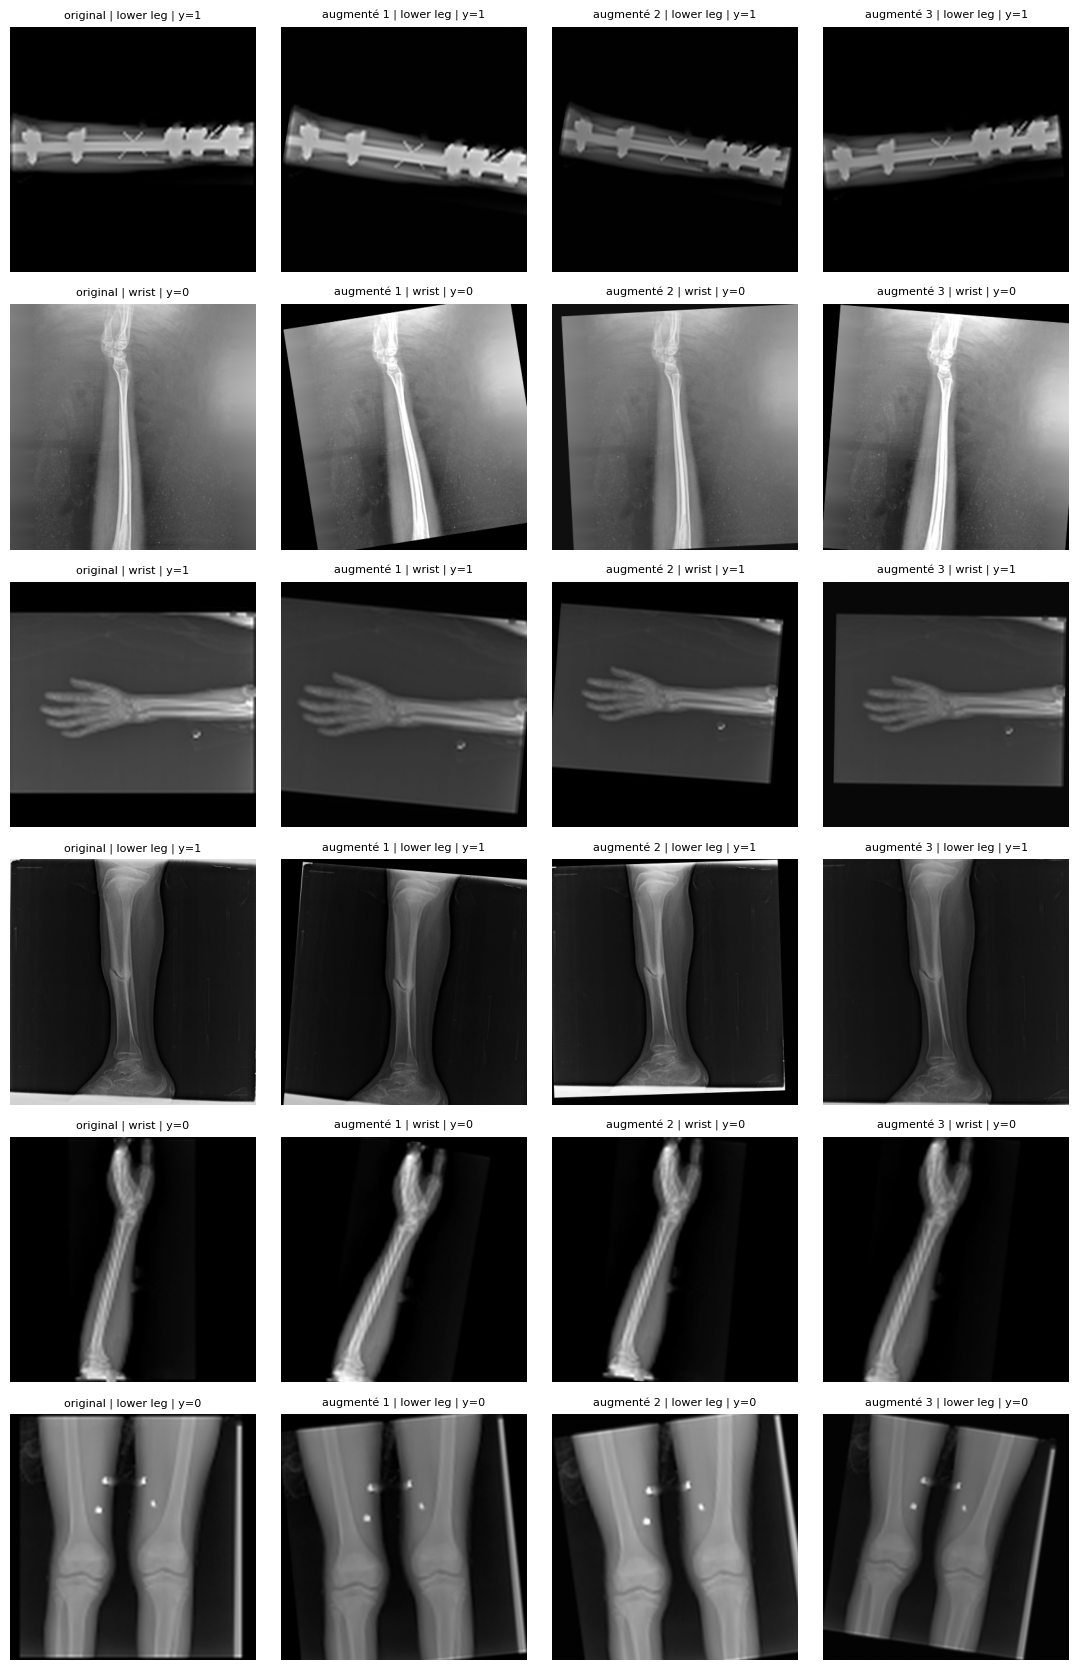

À vérifier : anatomie préservée, aucun signe de fracture masqué, fond noir aux bords, contraste plausible.


In [ ]:
# VALIDATION VISUELLE DES AUGMENTATIONS (exigée par le protocole avant intégration)
gen_vis = torch.Generator(device=dev).manual_seed(123)
sel = idx["train"][np.random.RandomState(0).choice(len(idx["train"]), 6, replace=False)]
x0 = torch.from_numpy(X_all[sel]).to(dev).float().div(255).unsqueeze(1)
versions = [x0] + [augment_batch(x0, gen_vis) for _ in range(3)]
fig, axes = plt.subplots(len(sel), 4, figsize=(11, 2.8 * len(sel)))
for r in range(len(sel)):
    for c in range(4):
        axes[r, c].imshow(versions[c][r, 0].cpu().numpy(), cmap="gray", vmin=0, vmax=1); axes[r, c].axis("off")
        axes[r, c].set_title(("original" if c == 0 else f"augmenté {c}") + f" | {samp.region[sel[r]]} | y={int(y_all[sel[r]])}", fontsize=8)
plt.tight_layout(); plt.show()
print("À vérifier : anatomie préservée, aucun signe de fracture masqué, fond noir aux bords, contraste plausible.")

## 3. Modèles A et B et vérifications de cohérence

- **A** : ConvNeXt-Tiny ImageNet.
- **B** : A + `CBAMGate` après les étages 3 et 4. Avec F la sortie d'un étage : F′ = M_c(F) ⊙ F avec M_c = 2·σ(MLP(GAP(F)) + MLP(GMP(F))), puis **F_out = M_s(F′) ⊙ F′** avec M_s = 2·σ(conv₇ₓ₇([moyenne_c(F′); max_c(F′)])). La dernière couche du MLP et la convolution sont initialisées à 0 : M_c = M_s = 1 donc F_out = F à l'initialisation, et les poids d'attention reçoivent des gradients dès le début.
- Dans les deux cas, seule la couche linéaire finale (`head.fc`) est réinitialisée, de façon identique pour une graine donnée.
- La couche linéaire finale (`head.fc`, réinitialisée) reçoit un learning rate multiplié par `new_lr_mult`, dans A comme dans B. Les modules CBAM gardent le learning rate du backbone (`attn_lr_mult = 1`) : avec un learning rate majoré, leurs masques saturaient dès les premiers pas.

In [ ]:
class CBAMGate(nn.Module):
    """CBAM (attention de canal puis spatiale) à initialisation identité : masques 2*sigmoid(z), dernière couche initialisée à 0.
    Masque = 1 partout à l'initialisation (sortie = entrée) ET gradients non nuls vers les poids d'attention dès le début."""
    def __init__(self, channels, reduction=16, kernel_size=7):
        super().__init__()
        hidden = max(channels // reduction, 8)
        self.mlp = nn.Sequential(nn.Linear(channels, hidden), nn.ReLU(inplace=True), nn.Linear(hidden, channels))
        self.spatial = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2)
        for layer in (self.mlp[2], self.spatial):
            nn.init.zeros_(layer.weight); nn.init.zeros_(layer.bias)
        self._dev = None
    def forward(self, x):
        b, c = x.shape[:2]
        # entrées normalisées : l'échelle des activations de ConvNeXt est grande et ferait saturer les masques en quelques pas
        avg = F.layer_norm(x.mean(dim=(2, 3)).float(), (c,)); mx = F.layer_norm(x.amax(dim=(2, 3)).float(), (c,))
        mc = (2 * torch.sigmoid(self.mlp(avg) + self.mlp(mx))).view(b, c, 1, 1)
        f1 = x * mc
        s_in = torch.cat([f1.mean(1, keepdim=True), f1.amax(1, keepdim=True)], dim=1).float()
        s_in = (s_in - s_in.mean(dim=(2, 3), keepdim=True)) / (s_in.std(dim=(2, 3), keepdim=True) + 1e-5)
        ms = 2 * torch.sigmoid(self.spatial(s_in))
        self._dev = ((mc - 1).abs().mean() + (ms - 1).abs().mean()).detach()       # écart moyen des masques à 1 (pour le journal)
        return f1 * ms

# Groupes de paramètres : couche linéaire finale (head.fc) et modules CBAM (stages.2.1.* et stages.3.1.*)
HEAD_RE = re.compile(r"^head\.fc\.")
ATTN_RE = re.compile(r"^stages\.[23]\.1\.")

def reset_head(model, seed):
    """Réinitialise UNIQUEMENT la couche linéaire finale, de façon identique pour une graine donnée."""
    torch.manual_seed(seed)
    nn.init.trunc_normal_(model.head.fc.weight, std=0.02)
    nn.init.zeros_(model.head.fc.bias)

def build_model(exp, seed):
    assert exp in ("A", "B")
    m = timm.create_model(ARCH, pretrained=True, num_classes=1, drop_rate=CFG["drop_rate"], drop_path_rate=CFG["drop_path_rate"])
    reset_head(m, seed)
    if exp == "B":
        m.stages[2] = nn.Sequential(m.stages[2], CBAMGate(384))
        m.stages[3] = nn.Sequential(m.stages[3], CBAMGate(768))
    return m.to(dev)

count = lambda m: sum(p.numel() for p in m.parameters())
count_re = lambda m, rx: sum(p.numel() for n, p in m.named_parameters() if rx.match(n))

In [ ]:
# VÉRIFICATIONS DE COHÉRENCE
from timm.data import resolve_data_config
dc = resolve_data_config({}, model=timm.create_model(ARCH, pretrained=False))
print("Normalisation timm des poids ImageNet :", dc["mean"], dc["std"])
assert np.allclose(dc["mean"], CFG["mean"]) and np.allclose(dc["std"], CFG["std"]), "normalisation ≠ configuration timm"

mA, mB = build_model("A", 42).eval(), build_model("B", 42).eval()
print(f"Paramètres : A = {count(mA):,} | B = {count(mB):,} (+{count(mB)-count(mA):,}, {100*(count(mB)-count(mA))/count(mA):.2f} %)")
print(f"Tête (lr x{CFG['new_lr_mult']:g}) : A = {count_re(mA, HEAD_RE):,} | B = {count_re(mB, HEAD_RE):,} ; attention (lr x{CFG['attn_lr_mult']:g}) : A = {count_re(mA, ATTN_RE):,} | B = {count_re(mB, ATTN_RE):,}")
assert count_re(mA, HEAD_RE) == 769 == count_re(mB, HEAD_RE) and count_re(mA, ATTN_RE) == 0 and count_re(mB, ATTN_RE) == count(mB) - count(mA), "groupes de paramètres inattendus"
assert torch.equal(mA.head.fc.weight, mB.head.fc.weight), "têtes initialisées différemment"
x = torch.randn(4, 3, 384, 384, device=dev)
with torch.no_grad():
    dAB = (mA(x) - mB(x)).abs().max().item()
print(f"Écart max des sorties A vs B à l'initialisation : {dAB:.2e} (doit être ~0)")
assert dAB < 1e-4, "B n'est pas neutre à l'initialisation"
# Les poids d'attention doivent recevoir un gradient non nul dès le début (contrairement à la forme à porte gamma de la v1)
mB.train(); mB.zero_grad()
mB(x[:2]).sum().backward()
g_last = [p.grad.abs().sum().item() for n, p in mB.named_parameters() if n.endswith("mlp.2.weight") or n.endswith("spatial.weight")]
print("Norme L1 du gradient des couches finales d'attention :", [f"{g:.3e}" for g in g_last])
assert all(g > 0 for g in g_last), "gradient d'attention nul : l'attention ne pourrait pas apprendre"
del mA, mB, x; torch.cuda.empty_cache()
print("Vérifications OK")

Normalisation timm des poids ImageNet : (0.485, 0.456, 0.406) (0.229, 0.224, 0.225)


model.safetensors: reconstructing file:   0%|          |  0.00B /  114MB            

model.safetensors: downloading bytes:           |  0.00B            

Paramètres : A = 27,820,897 | B = 27,914,479 (+93,582, 0.34 %)
Tête (lr x10) : A = 769 | B = 769 ; attention (lr x1) : A = 0 | B = 93,582
Écart max des sorties A vs B à l'initialisation : 0.00e+00 (doit être ~0)
Norme L1 du gradient des couches finales d'attention : ['1.813e+01', '1.515e-07', '5.842e+01', '9.590e-01']
Vérifications OK


## 4. Boucle d'entraînement et évaluation

Pour une graine donnée, A et B voient **les mêmes images dans le même ordre avec les mêmes tirages d'augmentation**. Trois modes : test rapide (`smoke`), pilote du learning rate (`pilot` : validation seule, le test n'est ni calculé ni sauvegardé) et entraînement complet.

In [ ]:
REVEAL_TEST = False   # True uniquement pour l'analyse finale : le test ne doit influencer aucun choix de développement
import copy

def set_seed(seed):
    random.seed(seed); np.random.seed(seed); torch.manual_seed(seed); torch.cuda.manual_seed_all(seed)

def make_optimizer(model):
    """AdamW ; poids de dimension >= 2 avec weight decay, biais/normalisations sans ; tête x new_lr_mult, attention x attn_lr_mult."""
    mult = {"head": CFG["new_lr_mult"], "attn": CFG["attn_lr_mult"], "base": 1.0}
    groups = {}
    for n, p in model.named_parameters():
        kind = "head" if HEAD_RE.match(n) else ("attn" if ATTN_RE.match(n) else "base")
        groups.setdefault((kind, p.ndim >= 2), []).append(p)
    pg = [{"params": ps, "weight_decay": CFG["weight_decay"] if dec else 0.0, "lr": CFG["lr"] * mult[kind]} for (kind, dec), ps in groups.items()]
    return torch.optim.AdamW(pg, lr=CFG["lr"])

class SimpleEMA:
    """Moyenne mobile exponentielle des poids ; le coefficient monte progressivement au début de l'entraînement."""
    def __init__(self, model, decay):
        self.module = copy.deepcopy(model).eval()
        for p in self.module.parameters():
            p.requires_grad_(False)
        self.decay = decay
        self.e = list(self.module.state_dict().values())      # tenseurs de l'EMA (modifiés en place)
        self.m = list(model.state_dict().values())            # tenseurs vivants du modèle (même mémoire que ses paramètres)
        assert all(t.dtype.is_floating_point for t in self.e), "tampon non flottant : EMA non prévue"
    @torch.no_grad()
    def update(self, step):
        d = min(self.decay, (1 + step) / (10 + step))
        torch._foreach_mul_(self.e, d)
        torch._foreach_add_(self.e, self.m, alpha=1 - d)

@torch.inference_mode()
def predict(model, ids, amp=True, bs=64):
    model.eval(); out = []
    for s in range(0, len(ids), bs):
        with torch.autocast("cuda", dtype=torch.float16, enabled=amp):
            lo = model(to_input(X_all[ids[s:s + bs]]))
        out.append(torch.sigmoid(lo.float()).squeeze(1).cpu().numpy())
    return np.concatenate(out)

def stratified_subset(ids, n):
    h = n // 2
    return np.concatenate([ids[y_all[ids] == 0][:h], ids[y_all[ids] == 1][:h]])

def attn_log(model):
    """Écart moyen des masques d'attention à 1 (0 = attention inactive) pour B ; vide pour A."""
    gates = [m for m in model.modules() if isinstance(m, CBAMGate) and m._dev is not None]
    return {f"attn_dev_stage{3 + i}": float(m._dev.item()) for i, m in enumerate(gates)}

def run_experiment(exp, seed, smoke=False, pilot=False, tag=""):
    root = "runs_v2_smoke" if smoke else ("runs_v2_pilot" if pilot else "runs_v2")
    out_dir = BASE / root / f"exp{exp}_seed{seed}{'_' + tag if tag else ''}"
    label = f"[exp {exp} | graine {seed}{' | ' + tag if tag else ''}]"
    if not smoke and (out_dir / "result.json").exists():
        print(f"{label} déjà terminé : ignoré"); return json.load(open(out_dir / "result.json"))
    out_dir.mkdir(parents=True, exist_ok=True)
    set_seed(seed)
    tr, va, te = idx["train"], idx["valid"], idx["test"]
    if smoke:
        tr, va, te = stratified_subset(tr, 256), stratified_subset(va, 128), stratified_subset(te, 128)
    epochs = 1 if smoke else CFG["epochs"]; bs = CFG["batch_size"]
    model = build_model(exp, seed); n_params = count(model)
    ema = SimpleEMA(model, CFG["ema_decay"]) if CFG["ema_decay"] else None
    eval_model = ema.module if ema else model
    print(f"{label} lr de pointe {CFG['lr']:g} (tête x{CFG['new_lr_mult']:g} : {count_re(model, HEAD_RE):,} paramètres ; attention x{CFG['attn_lr_mult']:g} : {count_re(model, ATTN_RE):,}) | EMA {CFG['ema_decay']} | {epochs} époques max")
    opt = make_optimizer(model)
    spe = math.ceil(len(tr) / bs); total = epochs * spe; warm = CFG["warmup_epochs"] * spe
    def lr_lambda(step):
        if step < warm:
            return (step + 1) / warm
        prog = (step - warm) / max(total - warm, 1)
        return CFG["min_lr_ratio"] + (1 - CFG["min_lr_ratio"]) * 0.5 * (1 + math.cos(math.pi * prog))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lr_lambda)
    try:
        scaler = torch.amp.GradScaler("cuda", enabled=CFG["amp"])
    except Exception:
        scaler = torch.cuda.amp.GradScaler(enabled=CFG["amp"])
    g_data = torch.Generator().manual_seed(seed)                       # ordre des images : identique entre A et B
    g_aug = torch.Generator(device=dev).manual_seed(seed)              # tirages d'augmentation : identiques entre A et B
    loss_fn = nn.BCEWithLogitsLoss()
    best_auc, best_ep, bad, hist, gstep = -1.0, -1, 0, [], 0
    t_start = time.time()
    for ep in range(epochs):
        model.train(); t0 = time.time(); run_loss = 0.0
        perm = tr[torch.randperm(len(tr), generator=g_data).numpy()]
        for s in range(0, len(perm), bs):
            b = perm[s:s + bs]
            xb = to_input(X_all[b], g_aug, train=True)
            yb = torch.from_numpy(y_all[b]).to(dev)
            with torch.autocast("cuda", dtype=torch.float16, enabled=CFG["amp"]):
                lo = model(xb).squeeze(1)
            loss = loss_fn(lo.float(), yb)
            opt.zero_grad(set_to_none=True)
            scaler.scale(loss).backward()
            scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(model.parameters(), CFG["grad_clip"])
            scaler.step(opt); scaler.update(); sched.step()
            if ema:
                ema.update(gstep)
            gstep += 1
            run_loss += loss.item() * len(b)
        assert math.isfinite(run_loss), "perte non finie"
        auc_raw = float(roc_auc_score(y_all[va], predict(model, va))) if ema else None      # modèle brut (journal)
        auc = float(roc_auc_score(y_all[va], predict(eval_model, va)))                       # modèle évalué et sélectionné (EMA si activée)
        hist.append({"epoch": ep + 1, "train_loss": run_loss / len(tr), "val_auc": auc, "val_auc_raw": auc_raw if ema else auc,
                     "lr": opt.param_groups[0]["lr"], "sec": time.time() - t0, **attn_log(model)})
        atxt = (" | écart des masques à 1 : " + ", ".join(f"{v:.4f}" for k, v in hist[-1].items() if k.startswith("attn"))) if exp == "B" else ""
        rtxt = f" (brut {auc_raw:.4f})" if ema else ""
        print(f"{label} ép {ep + 1}/{epochs} | perte {run_loss / len(tr):.4f} | AUC val {auc:.4f}{rtxt} | lr {opt.param_groups[0]['lr']:.2e} | {time.time() - t0:.0f} s{atxt}")
        if auc > best_auc + 1e-6:
            best_auc, best_ep, bad = auc, ep + 1, 0
            torch.save(eval_model.state_dict(), out_dir / "best.pt")
        else:
            bad += 1
            if bad >= CFG["patience"]:
                print(f"  arrêt anticipé (patience {CFG['patience']}) ; meilleure époque : {best_ep}"); break
    train_sec = time.time() - t_start
    eval_model.load_state_dict(torch.load(out_dir / "best.pt", map_location=dev))
    pd.DataFrame(hist).to_csv(out_dir / "history.csv", index=False)
    if pilot:      # VALIDATION SEULE : le test n'est ni calculé ni sauvegardé
        p_val = predict(eval_model, va, amp=False)
        res = {"exp": exp, "seed": seed, "tag": tag, "lr": CFG["lr"], "ema": CFG["ema_decay"], "best_epoch": best_ep,
               "best_val_auc": float(roc_auc_score(y_all[va], p_val)), "epochs_run": len(hist), "final_train_loss": hist[-1]["train_loss"],
               "val_auc_curve": [h["val_auc"] for h in hist], "val_auc_raw_curve": [h["val_auc_raw"] for h in hist], "train_sec": train_sec}
        json.dump(res, open(out_dir / "result.json", "w"), indent=1)
        print(f"{label} PILOTE : meilleure époque {best_ep} | AUC val {res['best_val_auc']:.4f} | max brut {max(res['val_auc_raw_curve']):.4f}")
        del model, ema, opt; torch.cuda.empty_cache(); return res
    # Évaluation finale avec le MEILLEUR modèle (sélection sur la validation), en précision normale
    p_val, p_te = predict(eval_model, va, amp=False), predict(eval_model, te, amp=False)
    S = summarize_predictions(y_all[va], p_val, y_all[te], p_te, CFG["target_recall"])
    S.update({"exp": exp, "seed": seed, "smoke": smoke, "n_params": n_params, "best_epoch": best_ep, "best_val_auc_amp": best_auc,
              "epochs_run": len(hist), "train_sec": train_sec, "cfg": CFG, "attn_final": attn_log(model),
              "versions": {"torch": torch.__version__, "timm": timm.__version__, "gpu": torch.cuda.get_device_name(0)}})
    for name, ids, p in (("valid", va, p_val), ("test", te, p_te)):
        pd.DataFrame({"rel_path": samp.rel_path.values[ids], "label": y_all[ids].astype(int), "prob": p}).to_csv(out_dir / f"{name}_predictions.csv", index=False)
    json.dump(S, open(out_dir / "result.json", "w"), indent=1)
    if smoke:
        (out_dir / "best.pt").unlink(missing_ok=True)
    v = S["val"]["at_target"]
    msg = (f"{label} meilleure époque {best_ep} | VALIDATION : AUC {S['val']['auc']:.4f} | seuil {S['threshold']:.4f} "
           f"-> rappel {v['recall']:.3f}, spécificité {v['specificity']:.3f}")
    if REVEAL_TEST:
        t = S["test"]; a = t["at_target"]
        msg += f" || TEST : AUC {t['auc']:.4f} -> rappel {a['recall']:.3f}, spécificité {a['specificity']:.3f}"
    print(msg + (f" | écart des masques à 1 : {S['attn_final']}" if exp == "B" else ""))
    del model, ema, opt; torch.cuda.empty_cache()
    return S

def pilot_lr(lrs=(5e-5, 2e-5), exp="A", seed=42):
    """Compare des learning rates de pointe sur la VALIDATION seule (graine 42, modèle de référence A). Journalise EMA et modèle brut."""
    old, res = CFG["lr"], {}
    try:
        for lr in lrs:
            CFG["lr"] = lr
            res[lr] = run_experiment(exp, seed, pilot=True, tag=f"lr{lr:g}")
    finally:
        CFG["lr"] = old
    tab = pd.DataFrame([{"lr": lr, "meilleure époque": r["best_epoch"], "AUC val max (évalué)": round(r["best_val_auc"], 4),
                         "AUC val max (brut)": round(max(r.get("val_auc_raw_curve", r["val_auc_curve"])), 4), "époques": r["epochs_run"],
                         "perte train finale": round(r["final_train_loss"], 3),
                         "écart-type AUC val (instabilité)": round(float(np.std(r["val_auc_curve"][1:])), 4) if len(r["val_auc_curve"]) > 2 else np.nan}
                        for lr, r in res.items()])
    print("\nPilote du learning rate (validation seule) :"); print(tab.to_string(index=False))
    return res

## 5. Test rapide (obligatoire avant tout)

256 images d'entraînement, 128 de validation, 128 de test, 1 époque, graine 42, A et B. Il ne sert qu'à vérifier que tout tourne de bout en bout ; ses métriques n'ont aucune signification. Écrit dans `runs_v2_smoke/`.

In [ ]:
smoke = [run_experiment(e, 42, smoke=True) for e in ("A", "B")]
tab = pd.DataFrame([{"exp": r["exp"], "paramètres": r["n_params"], "AUC val": round(r["val"]["auc"], 3), "secondes": round(r["train_sec"]), **r["attn_final"]} for r in smoke])
print(tab.to_string(index=False))
print("\nContrôle : l'écart des masques d'attention à 1 doit être non nul pour B (le gradient atteint bien les modules d'attention).")

[exp A | graine 42] lr de pointe 2e-05 (tête x10 : 769 paramètres ; attention x1 : 0) | EMA 0.999 | 1 époques max
[exp A | graine 42] ép 1/1 | perte 0.7045 | AUC val 0.5901 (brut 0.6382) | lr 2.00e-05 | 13 s
[exp A | graine 42] meilleure époque 1 | VALIDATION : AUC 0.5920 | seuil 0.4417 -> rappel 0.906, spécificité 0.094
[exp B | graine 42] lr de pointe 2e-05 (tête x10 : 769 paramètres ; attention x1 : 93,582) | EMA 0.999 | 1 époques max
[exp B | graine 42] ép 1/1 | perte 0.7045 | AUC val 0.5917 (brut 0.6384) | lr 2.00e-05 | 4 s | écart des masques à 1 : 0.0001, 0.0005
[exp B | graine 42] meilleure époque 1 | VALIDATION : AUC 0.5933 | seuil 0.4416 -> rappel 0.906, spécificité 0.094 | écart des masques à 1 : {'attn_dev_stage3': 0.00014066696166992188, 'attn_dev_stage4': 0.0005135536193847656}
exp  paramètres  AUC val  secondes  attn_dev_stage3  attn_dev_stage4
  A    27820897    0.592        14              NaN              NaN
  B    27914479    0.593         5         0.000141        

## 7. Entraînements complets : A et B × 3 graines

Renseigner d'abord le learning rate retenu au pilote. Chaque entraînement terminé écrit `runs_v2/exp{A|B}_seed{S}/result.json` ; relancer après une déconnexion saute ceux déjà faits. Ordre : graine par graine, pour obtenir tôt une comparaison A/B complète.

In [ ]:
CFG["lr"] = 2e-5      # valeur retenue au pilote (validation seule)
print("Learning rate de pointe retenu :", CFG["lr"], "| tête :", CFG["lr"] * CFG["new_lr_mult"], "| attention :", CFG["lr"] * CFG["attn_lr_mult"])
RUNS = [(e, s) for s in SEEDS for e in ("A", "B")]
results = {}
for e, s in RUNS:
    results[(e, s)] = run_experiment(e, s)

Learning rate de pointe retenu : 2e-05 | tête : 0.0002 | attention : 2e-05
[exp A | graine 42] déjà terminé : ignoré
[exp B | graine 42] déjà terminé : ignoré
[exp A | graine 123] déjà terminé : ignoré
[exp B | graine 123] déjà terminé : ignoré
[exp A | graine 2024] déjà terminé : ignoré
[exp B | graine 2024] déjà terminé : ignoré


## 8. Agrégation, comparaison A contre B et ensemble de graines

Moyenne ± écart-type sur les graines, comparaison appariée A/B par bootstrap sur les images de test, AUC par région. L'**ensemble de graines** (moyenne des probabilités des 3 modèles) est une pratique légitime à condition d'être déclarée comme telle ; le seuil y est fixé sur la validation de l'ensemble.

In [ ]:
df_runs, df_comp, df_reg = aggregate(BASE / "runs_v2", samp, exps=("A", "B"), pairs=(("A", "B"),))
ens = ensemble_report(BASE / "runs_v2", ("A", "B"), SEEDS)

Jeu de TEST, au seuil déterminé sur la validation (rappel cible) — moyenne ± écart-type sur les graines :
     graines          ROC-AUC           PR-AUC         accuracy        precision           recall      specificity               f1
exp                                                                                                                                
A          3  0.9164 ± 0.0016  0.8686 ± 0.0011  0.7578 ± 0.0065  0.5448 ± 0.0079  0.8975 ± 0.0106  0.7024 ± 0.0124  0.6779 ± 0.0044
B          3   0.916 ± 0.0007   0.8681 ± 0.001  0.7569 ± 0.0178    0.544 ± 0.021  0.8998 ± 0.0036  0.7002 ± 0.0256  0.6779 ± 0.0158

Comparaisons appariées (bootstrap sur les images de test, AUC moyennée sur les graines) :
  comparaison  ΔAUC moyen             IC95 %  0 dans l'IC
exp B - exp A     -0.0004 [-0.0021 ; 0.0014]         True

AUC par région (test, moyenne sur les graines) ; effectifs de fractures parfois faibles : prudence
exp            A      B
région                 
arm        

In [ ]:
import numpy as np, pandas as pd
from pathlib import Path
from sklearn.metrics import roc_auc_score

# ====== À ADAPTER : les deux dossiers ======
BASE_3 = Path("/content/drive/MyDrive/Bonefract")      # contient runs_base/ (ResNet, DenseNet, Swin)
DIR_CNX = Path("/content/drive/MyDrive/Bonefract/runs_v2")   # dossier qui contient expA_seed42, expA_seed123, expA_seed2024
SEEDS = [42, 123, 2024]
# ===========================================

dossiers = {
    "ResNet-50":    [BASE_3 / "runs_base" / f"expresnet50_seed{s}" for s in SEEDS],
    "DenseNet-121": [BASE_3 / "runs_base" / f"expdensenet121_seed{s}" for s in SEEDS],
    "Swin-T":       [BASE_3 / "runs_base" / f"expswin_t_seed{s}" for s in SEEDS],
    "ConvNeXt-T":   [DIR_CNX / f"expA_seed{s}" for s in SEEDS],
}

# Vérification des fichiers
manque = [str(d / "test_predictions.csv") for ds in dossiers.values() for d in ds
          if not (d / "test_predictions.csv").exists()]
if manque:
    print("FICHIERS MANQUANTS :"); [print(" -", m) for m in manque]
    raise SystemExit("Corrige les chemins en haut de la cellule.")

# Chargement : on aligne sur les images communes à tous les modèles
preds = {n: [pd.read_csv(d / "test_predictions.csv").set_index("rel_path") for d in ds]
         for n, ds in dossiers.items()}
communs = set.intersection(*[set(df.index) for dfs in preds.values() for df in dfs])
ref = preds["ConvNeXt-T"][0]
idx = [i for i in ref.index if i in communs]
print(f"Images de test communes : {len(idx)} (ConvNeXt : {len(ref)})")
assert len(idx) == len(ref), "Les jeux de test ne sont pas identiques : vérifie que les 4 modèles viennent du même échantillon."
y = ref.loc[idx, "label"].values
for n, dfs in preds.items():
    for df in dfs:
        assert (df.loc[idx, "label"].values == y).all(), f"Étiquettes différentes pour {n}"
P = {n: np.array([df.loc[idx, "prob"].values for df in dfs]) for n, dfs in preds.items()}   # (3, N)

# Bootstrap apparié
rng = np.random.default_rng(0)
B, N = 1000, len(y)
boot = {n: [] for n in P}
for _ in range(B):
    i = rng.integers(0, N, N)
    if y[i].min() == y[i].max():
        continue
    for n in P:
        boot[n].append(np.mean([roc_auc_score(y[i], p[i]) for p in P[n]]))
boot = {n: np.array(v) for n, v in boot.items()}

rows = []
for n in P:
    lo, hi = np.percentile(boot[n], [2.5, 97.5])
    r = {"modele": n, "AUC_test": boot[n].mean(), "IC95_bas": lo, "IC95_haut": hi}
    if n != "ConvNeXt-T":
        d = boot["ConvNeXt-T"] - boot[n]                       # ConvNeXt moins l'autre modèle
        dlo, dhi = np.percentile(d, [2.5, 97.5])
        r.update({"ConvNeXt_moins_modele": d.mean(), "IC95_bas_diff": dlo, "IC95_haut_diff": dhi,
                  "p_approx": min(1.0, 2 * min((d <= 0).mean(), (d >= 0).mean()))})
    rows.append(r)
df_sig = pd.DataFrame(rows).set_index("modele").round(4)
df_sig.to_csv(BASE_3 / "comparaison_appariee.csv")
display(df_sig)

FICHIERS MANQUANTS :
 - /content/drive/MyDrive/Bonefract/runs_base/expresnet50_seed42/test_predictions.csv
 - /content/drive/MyDrive/Bonefract/runs_base/expresnet50_seed123/test_predictions.csv
 - /content/drive/MyDrive/Bonefract/runs_base/expresnet50_seed2024/test_predictions.csv
 - /content/drive/MyDrive/Bonefract/runs_base/expdensenet121_seed42/test_predictions.csv
 - /content/drive/MyDrive/Bonefract/runs_base/expdensenet121_seed123/test_predictions.csv
 - /content/drive/MyDrive/Bonefract/runs_base/expdensenet121_seed2024/test_predictions.csv
 - /content/drive/MyDrive/Bonefract/runs_base/expswin_t_seed42/test_predictions.csv
 - /content/drive/MyDrive/Bonefract/runs_base/expswin_t_seed123/test_predictions.csv
 - /content/drive/MyDrive/Bonefract/runs_base/expswin_t_seed2024/test_predictions.csv


SystemExit: Corrige les chemins en haut de la cellule.

/usr/local/lib/python3.13/dist-packages/IPython/core/interactiveshell.py:3561: UserWarning: To exit: use 'exit', 'quit', or Ctrl-D.
  warn("To exit: use 'exit', 'quit', or Ctrl-D.", stacklevel=1)
